# Cells without data

A partition fine enough leaves some of its cells without a single datum, and away from the data most
of them. What a location in such a cell receives decides what the ensemble says where the data say
little. Here we compare the three answers Spatialize offers on a field whose data cover only a corner,
so that part of the map lies far from any datum.

## Learning goals

- What the *residual weight* of a location is, and how `empty_cell_fraction()` estimates it.
- What `empty_cells="nan"`, `"mark"` and `"coarsen"` give a location in an empty cell.
- How each choice changes the map and, above all, the law far from the data.
- Where the marks come from, through `mark_source` and `mark_value`.

*What should an ensemble say where the data do not reach?*

## The idea

In the theory Spatialize rests on, the law of the value at a location $v$ mixes the data, each with a
weight given by how often a partition puts it in the cell of $v$, and one more term. The *residual
weight* $1 - \sum_i w_i(v)$ is the share of partitions whose cell around $v$ holds no datum. It is near
zero inside the sample and grows as $v$ moves away from it. On that share the data say nothing about
$v$, so the law falls back on the law of a value the sample does not reach.

The session setting `empty_cells` decides what a location gets from such a partition.

- `"nan"`, the default, gives no member, so the law at $v$ is the one conditioned on its cell holding
  data. Far from the data it rests on the few partitions that reach some datum.
- `"mark"` gives every location of the empty cell one shared value, its *mark*, drawn from cells with
  data, as the theory's block-mark model does. The law then carries the residual term.
- `"coarsen"` predicts the location with the decoder from the nearest coarser cell that holds data,
  a smooth continuation of the field.

The theory page [The block-mark model](https://spatialize.readthedocs.io/en/latest/theory/blockmark.html)
gives the details.

## Step by step

### Data in a corner

The field is an isotropic Gaussian simulation with an exponential covariance of range 8 on a 64 × 64
grid. The 200 data lie in the lower left corner, below 38 in both coordinates, while we estimate the
whole grid. The decoder is IDW, fair on a field without a preferred direction.

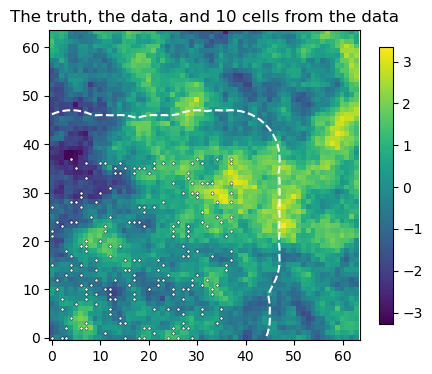

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.gs.esi import esi_griddata
import spatialize.gs.esi.functionals as fn

spatialize.session.set(progress=False)

m = 64
nodes = np.stack(np.meshgrid(np.arange(m), np.arange(m), indexing="ij"), -1).reshape(-1, 2).astype(float)
distance = np.sqrt(((nodes[:, None, :] - nodes[None, :, :]) ** 2).sum(-1))
rng = np.random.default_rng(5)
field = np.linalg.cholesky(np.exp(-distance / 8.0) + 1e-8 * np.eye(len(nodes))) @ rng.standard_normal(len(nodes))
corner = np.where((nodes[:, 0] < 38) & (nodes[:, 1] < 38))[0]
picked = rng.choice(corner, 200, replace=False)
points, values, truth = nodes[picked], field[picked], field.reshape(m, m)
xi = np.stack(np.meshgrid(np.arange(m, dtype=float), np.arange(m, dtype=float), indexing="ij"))

def band(result):
    # the 5 % and 95 % quantiles of the members at every grid node, NaN where none is defined
    members = result.esi_samples(raw=True)
    return fn.Percentile(5)(members).reshape(m, m), fn.Percentile(95)(members).reshape(m, m)

to_data = np.sqrt(((nodes[:, None, :] - points[None]) ** 2).sum(-1)).min(1).reshape(m, m)
near, far = to_data < 3, to_data > 10
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(truth.T, origin="lower", cmap="viridis")
ax.scatter(points[:, 0], points[:, 1], s=5, c="white", edgecolors="black", linewidths=0.3)
ax.contour(to_data.T, levels=[10], colors="white", linestyles="dashed")
ax.set_title("The truth, the data, and 10 cells from the data")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Beyond the dashed line every location lies more than 10 cells from the nearest datum, farther than
the range of the field.

### The residual weight

`empty_cell_fraction()` gives, at every location, the share of partitions whose cell held no datum, an
estimate of the residual weight. It reads the partitions alone, so it is the same whatever
`empty_cells` says.

residual weight near the data 0.02, far from them 0.83


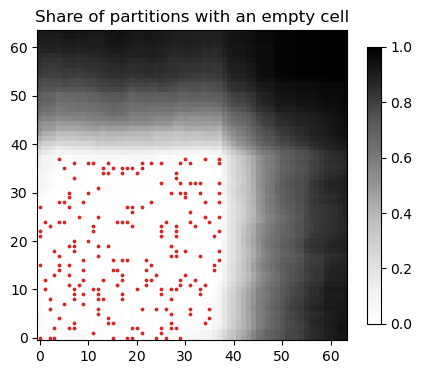

In [2]:
settings = dict(local_interpolator="idw", exponent=2.0, n_partitions=200, alpha=0.85, seed=0)
residual = esi_griddata(points, values, xi, **settings).empty_cell_fraction()
print(f"residual weight near the data {residual[near].mean():.2f}, far from them {residual[far].mean():.2f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(residual.T, origin="lower", cmap="Greys", vmin=0, vmax=1)
ax.scatter(points[:, 0], points[:, 1], s=3, c="C3")
ax.set_title("Share of partitions with an empty cell")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Inside the corner almost every partition has a datum in the cell of each location. Far from it, most
partitions have none, so most of the law there has to come from somewhere other than the data.

### Three answers

The same estimation runs under each policy, and under two sources for the marks, the default, which
draws among the 8 cells with data nearest to the empty cell, and the block-mark model exactly, one
datum of a cell drawn among all the cells with data. For each we measure the width of the 90 % band
of the members and how often it covers the truth, near the data and far from them.

In [3]:
policies = {"nan": {}, "mark, local": dict(empty_cells="mark"),
            "mark, block-mark": dict(empty_cells="mark", mark_source="cells", mark_value="datum"),
            "coarsen": dict(empty_cells="coarsen")}
results, rows = {}, {}
for name, policy in policies.items():
    with spatialize.session.override(**policy):
        r = esi_griddata(points, values, xi, **settings)
    low, high = band(r)
    covered = (truth >= low) & (truth <= high)
    error = np.abs(r.estimation() - truth)
    results[name] = (r.estimation(), high - low)
    rows[name] = {"band width, near": round(np.nanmean((high - low)[near]), 2),
                  "band width, far": round(np.nanmean((high - low)[far]), 2),
                  "coverage, near": round(np.nanmean(covered[near]), 2),
                  "coverage, far": round(np.nanmean(covered[far]), 2),
                  "error, far": round(np.nanmean(error[far]), 3)}
pd.DataFrame(rows).T

,"band width, near","band width, far","coverage, near","coverage, far","error, far"
nan,0.64,1.33,0.43,0.38,1.020
"mark, local",0.72,3.45,0.46,0.88,0.752
"mark, block-mark",0.74,3.98,0.46,0.94,0.762
coarsen,0.66,1.51,0.44,0.46,0.812


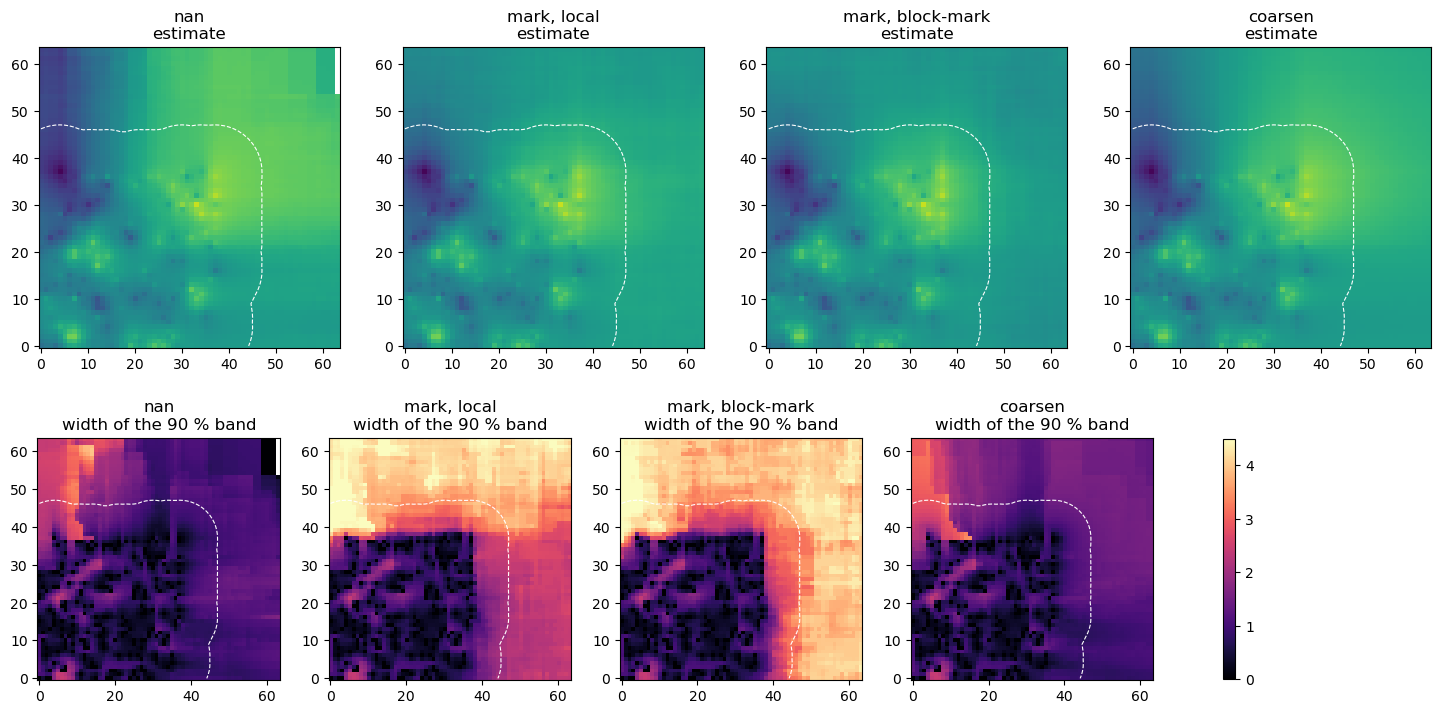

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.6))
for col, (name, (estimate, width)) in enumerate(results.items()):
    axes[0, col].imshow(estimate.T, origin="lower", cmap="viridis", vmin=truth.min(), vmax=truth.max())
    axes[0, col].set_title(f"{name}\nestimate")
    im = axes[1, col].imshow(width.T, origin="lower", cmap="magma", vmin=0, vmax=4.5)
    axes[1, col].set_title(f"{name}\nwidth of the 90 % band")
    for ax in axes[:, col]:
        ax.contour(to_data.T, levels=[10], colors="white", linestyles="dashed", linewidths=0.8)
fig.colorbar(im, ax=axes[1, :], shrink=0.8)
plt.show()

Near the data the four answers coincide, since there the residual weight is small. They part far
from the data. Under `"nan"` the estimate keeps repeating the nearest data, in stripes along the
axes, while its band stays narrow, so it covers the truth only rarely, as if the corner's data still
spoke there. A few locations in the far corner get no member at all and stay blank. Under `"mark"`
the band widens with the residual weight and covers the truth far more often, since the law now says
how little the data tell about those places, the block-mark source a little more than the local one.
Under `"coarsen"` the map continues the field smoothly, with the lowest error of a map far away
after the marks, while its band stays almost as narrow as under `"nan"`.

Inside the corner the coverage stays well below 90 % under every policy. There the averaging decoder
is to blame, not the empty cells, since its members miss the dispersion within a cell (the tutorial
on the decoders shows how a drawing decoder widens them).

### Along a transect

A transect from the middle of the corner out to the far edge shows the same thing location by
location.

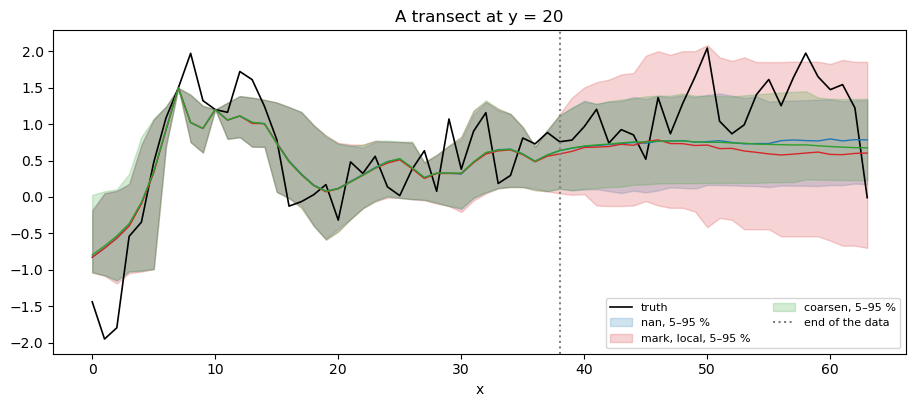

In [5]:
row = 20
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(np.arange(m), truth[:, row], color="black", lw=1.2, label="truth")
for name, color in (("nan", "C0"), ("mark, local", "C3"), ("coarsen", "C2")):
    with spatialize.session.override(**policies[name]):
        r = esi_griddata(points, values, xi, **settings)
    low, high = band(r)
    ax.fill_between(np.arange(m), low[:, row], high[:, row], color=color, alpha=0.2, label=f"{name}, 5–95 %")
    ax.plot(np.arange(m), r.estimation()[:, row], color=color, lw=1)
ax.axvline(38, color="0.5", ls=":", label="end of the data")
ax.set_xlabel("x"); ax.set_title(f"A transect at y = {row}")
ax.legend(ncol=2, fontsize=8)
plt.show()

Past the end of the data the three estimates flatten towards the level of the nearest data, while
the bands part. Those of `"nan"` and `"coarsen"` keep about the width they had inside, almost on top
of each other, while that of `"mark"` opens to the spread of the marks, wide enough to hold the truth
as it wanders away.

### Choosing a policy

| Purpose | `empty_cells` |
|---|---|
| a law that shows how little the data say far from them | `"mark"` |
| the theory's law exactly | `"mark"` with `mark_source="cells"`, `mark_value="datum"` |
| a smooth continuation of the map beyond the data | `"coarsen"` |
| cross-validation that keeps every datum in the score | `"mark"` or `"coarsen"` |
| the law conditioned on the cell holding data | `"nan"` (the default) |

## Pitfalls

- **Narrow bands far from the data.** Under `"nan"` and `"coarsen"` the band far away reflects the
  data near it, not the lack of data. Read `empty_cell_fraction()` alongside it, or use `"mark"`.
- **A score that drops data.** Under `"nan"`, a datum alone in its cell has no leave-one-out
  prediction and leaves the score, which then favours partitions too fine for the data (see
  *Choosing an ensemble with the Pareto search*).
- **Comparing results under different policies.** They estimate different laws far from the data.
  `effective_config` records the policy of each result.
- **Queries far outside the data.** No policy invents information there. The marks report the
  ignorance, while the other two hide it.

## Try it yourself

1. Raise `alpha` to 0.95 and watch the residual weight grow inside the corner too.
2. Use `mark_source="data"`, which weighs densely sampled zones more, and compare the band far away.
3. Replace IDW by the uniform draw (`local_interpolator="draw"`) and see the coverage inside the
   corner rise towards 90 %.

## Next

- *The session*, for `empty_cells` among the other settings.
- *The decoders*, for the drawing decoders that widen the band inside the data.
- *Uncertainty at a location*, to read the law each policy gives.
- The documentation's [The block-mark model](https://spatialize.readthedocs.io/en/latest/theory/blockmark.html)
  (theory) and [session reference](https://spatialize.readthedocs.io/en/latest/reference/session.html).